# Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/home/youssef/Downloads/DSS-Education_EN_20261016_113402.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5055, 9)


,ROW__INDEX,Indicator,Country,Nationality,Sex,Educational_level,Sector,Year,Value
0,0,Adult literacy rates,Bahrain,Nationals,Both sexes,Not applicable,Not applicable,Y2001,87.7
1,1,Adult literacy rates,Bahrain,Nationals,Female,Not applicable,Not applicable,Y2001,83.0
2,2,Adult literacy rates,Bahrain,Nationals,Male,Not applicable,Not applicable,Y2001,92.5
3,3,Adult literacy rates,Bahrain,Non-nationals,Both sexes,Not applicable,Not applicable,Y2001,85.1
4,4,Adult literacy rates,Bahrain,Non-nationals,Female,Not applicable,Not applicable,Y2001,84.8


# Data Quality

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5055 entries, 0 to 5054
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ROW__INDEX         5055 non-null   int64  
 1   Indicator          5055 non-null   str    
 2   Country            5055 non-null   str    
 3   Nationality        5055 non-null   str    
 4   Sex                5055 non-null   str    
 5   Educational_level  5055 non-null   str    
 6   Sector             5055 non-null   str    
 7   Year               5055 non-null   str    
 8   Value              4984 non-null   float64
dtypes: float64(1), int64(1), str(7)
memory usage: 817.7 KB


In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes,
    "unique_values": df.nunique(),
    "missing_values": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

print(overview)

                     dtype  unique_values  missing_values  missing_pct
ROW__INDEX           int64           5055               0      0.00000
Indicator              str              7               0      0.00000
Country                str             22               0      0.00000
Nationality            str              4               0      0.00000
Sex                    str              4               0      0.00000
Educational_level      str              6               0      0.00000
Sector                 str              4               0      0.00000
Year                   str             24               0      0.00000
Value              float64            822              71      1.40455


In [5]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(
    duplicate_count / len(df) * 100, 2
), "%")

Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [13]:
print("Unique:", df["ROW__INDEX"].nunique())
print("Duplicated:", df["ROW__INDEX"].duplicated().sum())

Unique: 5055
Duplicated: 0


# Missing Values

In [7]:
print(df["Indicator"].value_counts(dropna=False).to_string())

Indicator
Net enrolment rate in primary education (percent)                                      1197
Pupil-teacher ratio (percent)                                                          1065
Adult literacy rates                                                                    816
Youth literacy rates                                                                    798
Net enrolment rate in secondary education (percent)                                     755
Government expenditure on education as a percentage of GDP (percent)                    235
Expenditure on education as a percentage of total government expenditure  (percent)     189


In [8]:
print(sorted(df["Year"].astype(str).unique()))

['Y2000', 'Y2001', 'Y2002', 'Y2003', 'Y2004', 'Y2005', 'Y2006', 'Y2007', 'Y2008', 'Y2009', 'Y2010', 'Y2011', 'Y2012', 'Y2013', 'Y2014', 'Y2015', 'Y2016', 'Y2017', 'Y2018', 'Y2019', 'Y2020', 'Y2021', 'Y2022', 'Y2023']


In [14]:
print(df["Value"].describe())

count    4984.000000
mean       62.773315
std        36.229232
min         0.100000
25%        19.400000
50%        81.800000
75%        94.825000
max       102.000000
Name: Value, dtype: float64


In [16]:
categorical_cols = [
    "Country",
    "Nationality",
    "Sex",
    "Educational_level",
    "Sector"
]

for col in categorical_cols:
    print("\n" + df[col].value_counts(dropna=False).to_string())


Country
Kuwait                  817
Qatar                   653
State of Palestine      448
Jordan                  376
Oman                    346
Iraq                    343
Bahrain                 282
Yemen                   253
Egypt                   244
Morocco                 215
Syrian Arab Republic    165
Saudi Arabia            161
Mauritania              156
Tunisia                 119
Lebanon                  90
Comoros                  83
Sudan                    77
Somalia                  74
Algeria                  70
United Arab Emirates     61
Djibouti                 16
Libya                     6

Nationality
Total             2375
Not applicable    1489
Nationals          750
Non-nationals      441

Sex
Not applicable    1489
Both sexes        1218
Male              1182
Female            1166

Educational_level
Not applicable    3990
Primary            287
Secondary          259
Tertiary           196
Preparatory        193
Total              130

Sector
Not appl

In [21]:
# Remove the row identifier
df = df.drop(columns=["ROW__INDEX"])

# Convert Year to numeric
df["Year"] = df["Year"].str.replace("Y", "", regex=False).astype(int)

# Remove leading/trailing spaces from text columns
text_cols = df.select_dtypes(
    include=["object", "str"]
).columns

for col in text_cols:
    df[col] = df[col].str.strip()
    
# Fill missing Value with the median
df["Value"] = df["Value"].fillna(df["Value"].median())

In [22]:
# Check cleaning results
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nYear range:")
print(df["Year"].min(), "-", df["Year"].max())

print("\nUnique years:")
print(sorted(df["Year"].dropna().unique().tolist()))

print("\nMissing values:")
print(df.isna().sum())

print("\nValue range by indicator:")
print(
    df.groupby("Indicator")["Value"]
    .agg(["count", "min", "max", "mean"])
    .round(2)
)

Shape: (5055, 8)

Data types:
Indicator                str
Country                  str
Nationality              str
Sex                      str
Educational_level        str
Sector                   str
Year                   int64
Value                float64
dtype: object

Year range:
2000 - 2023

Unique years:
[2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

Missing values:
Indicator            0
Country              0
Nationality          0
Sex                  0
Educational_level    0
Sector               0
Year                 0
Value                0
dtype: int64

Value range by indicator:
                                                    count   min    max   mean
Indicator                                                                    
Adult literacy rates                                  816  25.4  100.0  86.89
Expenditure on education as a percentage of tot...    189   2.5 

In [23]:
overview = pd.DataFrame({
    "dtype": df.dtypes,
    "unique_values": df.nunique(),
    "missing_values": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

print(overview)

                     dtype  unique_values  missing_values  missing_pct
Indicator              str              7               0          0.0
Country                str             22               0          0.0
Nationality            str              4               0          0.0
Sex                    str              4               0          0.0
Educational_level      str              6               0          0.0
Sector                 str              4               0          0.0
Year                 int64             24               0          0.0
Value              float64            822               0          0.0


# Outliers

In [27]:
numeric_cols = df.select_dtypes(include="number").columns
outlier_results = []

for col in numeric_cols:
    s = df[col].dropna()

    if s.nunique() < 4:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        continue

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df[col] < lower) | (df[col] > upper)

    outlier_results.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": round(mask.mean() * 100, 2)
    })
    
outliers = pd.DataFrame(outlier_results)

if not outliers.empty:
    display(outliers.sort_values(
        "outlier_count", ascending=False
    ))
else:
    print("No columns met the screening criteria.")

,column,lower_bound,upper_bound,outlier_count,outlier_pct
0,Year,1992.0,2032.0,0,0.0
1,Value,-92.3,206.9,0,0.0


# EDA

In [ ]:
indicator_stats = (
    df.groupby("Indicator")["Value"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Minimum="min",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Maximum="max"
    )
    .round(2)
)

indicator_stats["IQR"] = (
    indicator_stats["Q3"] - indicator_stats["Q1"]
).round(2)

display(indicator_stats.sort_values("Mean", ascending=False))

,Count,Mean,Median,Std,Minimum,Q1,Q3,Maximum,IQR
Indicator,,,,,,,,,
Youth literacy rates,798,95.22,98.70,8.44,34.4,95.22,99.30,100.0,4.08
Adult literacy rates,816,86.89,92.85,15.01,25.4,85.10,96.30,100.0,11.20
Net enrolment rate in primary education (percent),1197,86.32,91.10,14.05,10.0,81.80,95.00,102.0,13.20
Net enrolment rate in secondary education (percent),755,62.31,69.70,25.97,6.0,37.50,86.00,98.3,48.50
Pupil-teacher ratio (percent),1065,16.73,14.90,8.64,3.3,11.00,19.60,64.0,8.60
Expenditure on education as a percentage of total government expenditure (percent),189,13.63,11.90,6.19,2.5,9.30,19.10,27.8,9.80
Government expenditure on education as a percentage of GDP (percent),235,4.39,4.40,1.90,0.1,2.65,5.85,9.7,3.20


In [41]:
from pathlib import Path
import re
from scipy.stats import pearsonr, spearmanr

PROJECT_DIR = Path(
    "/home/youssef/Desktop/Data_Projects/DSS_Education"
)

FOLDERS = {
    "trends": PROJECT_DIR / "plots" / "03_temporal_trends",
    "countries": PROJECT_DIR / "plots" / "04_country_comparisons",
    "gender": PROJECT_DIR / "plots" / "05_gender_analysis",
    "spending": PROJECT_DIR / "plots" / "06_spending_vs_outcomes",
    "reports": PROJECT_DIR / "reports",
}

for folder in FOLDERS.values():
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

def slugify(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return text.strip("_")

def save_plot(filename, folder):
    output_path = FOLDERS[folder] / filename

    plt.tight_layout()
    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close()

    print(f"Saved: {output_path}")

print("Output folders are ready.")

Output folders are ready.


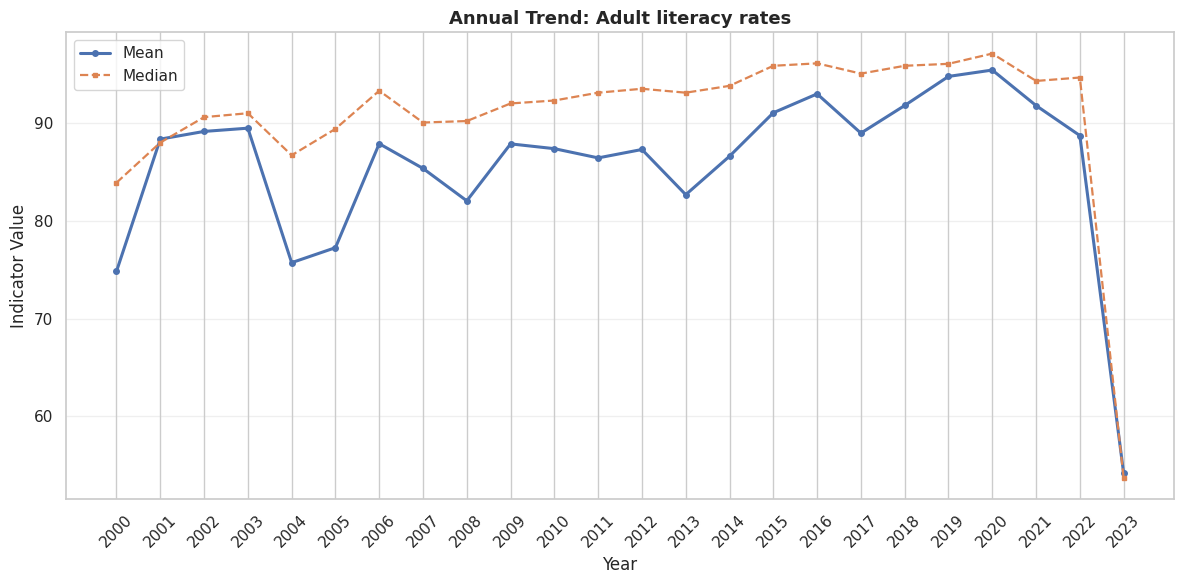

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_adult_literacy_rates.png


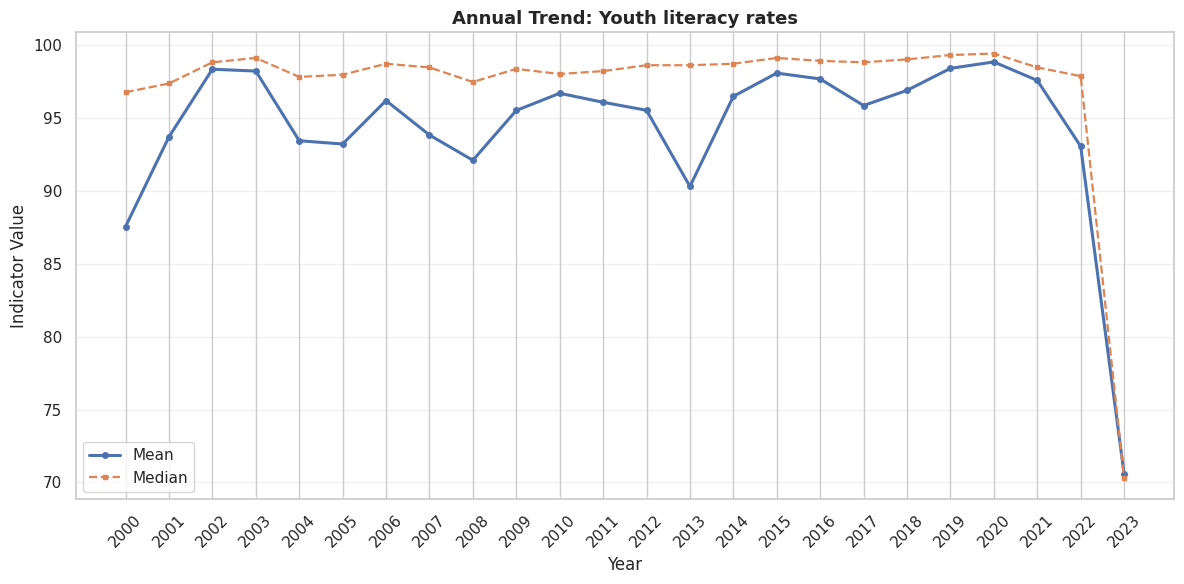

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_youth_literacy_rates.png


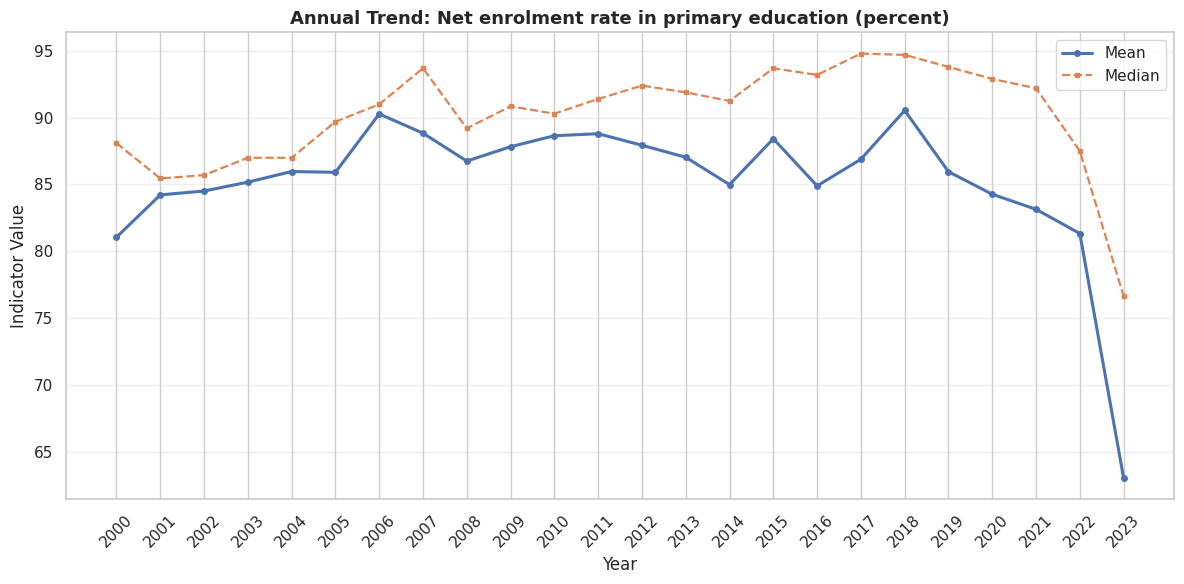

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_net_enrolment_rate_in_primary_education_percent.png


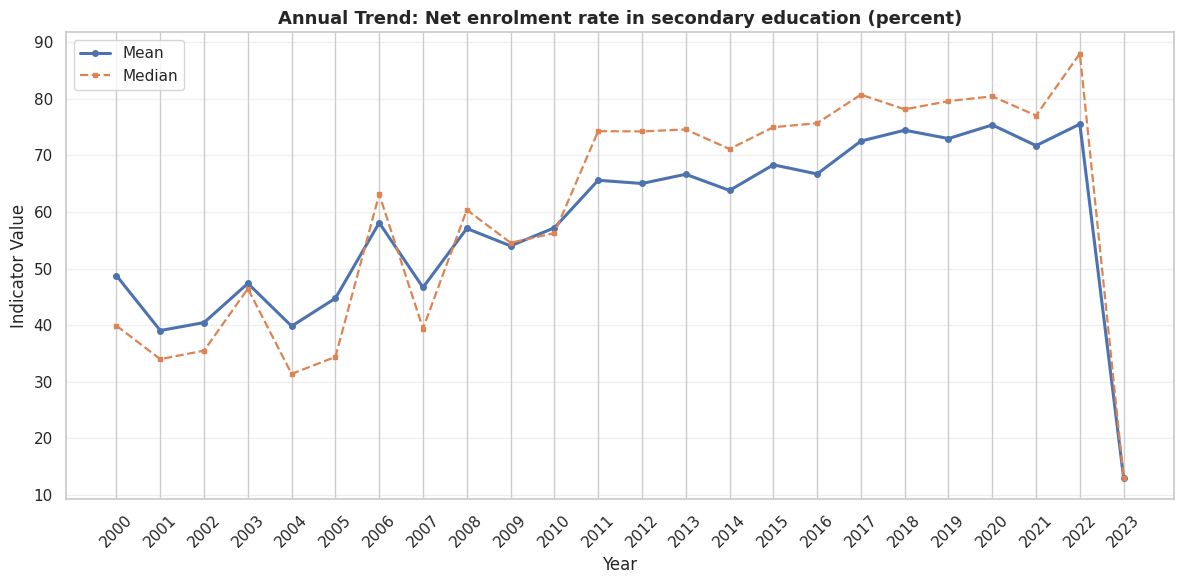

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_net_enrolment_rate_in_secondary_education_percent.png


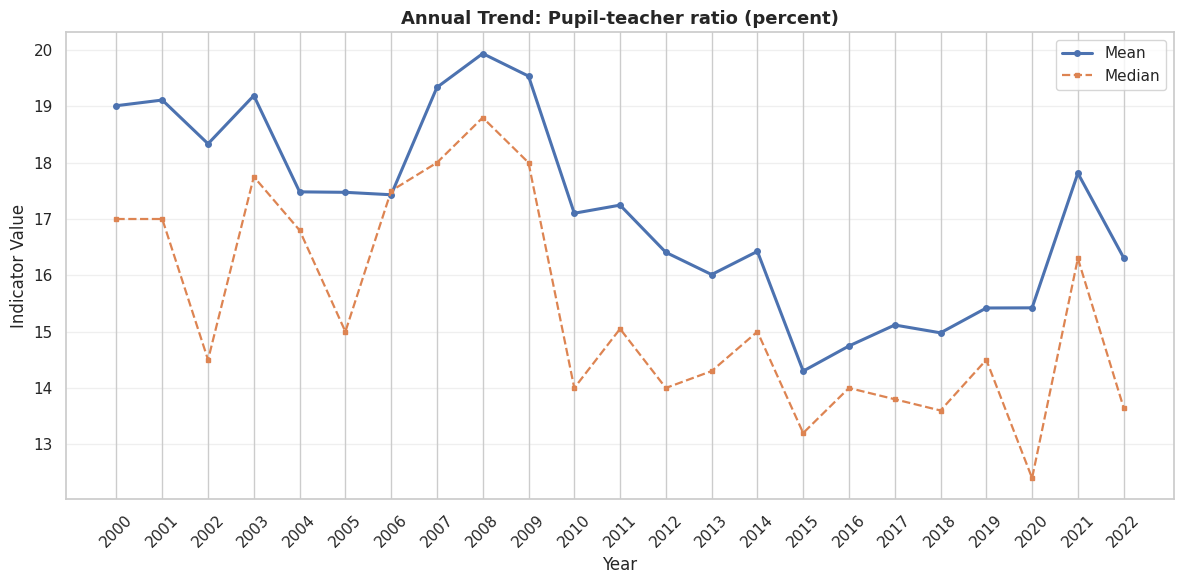

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_pupil_teacher_ratio_percent.png


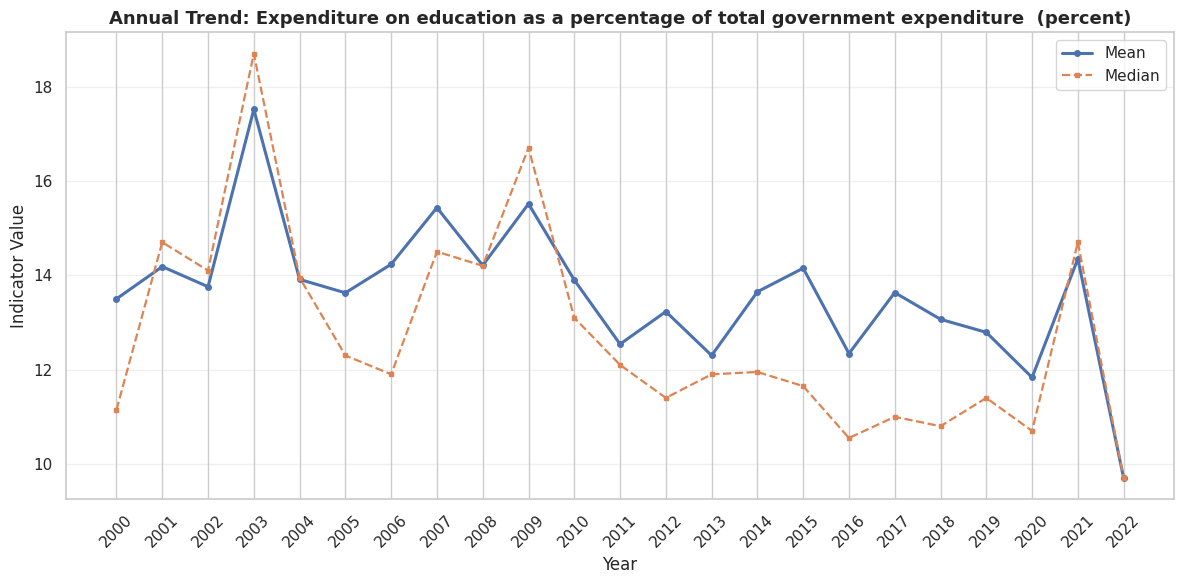

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_expenditure_on_education_as_a_percentage_of_total_government_expenditure_percent.png


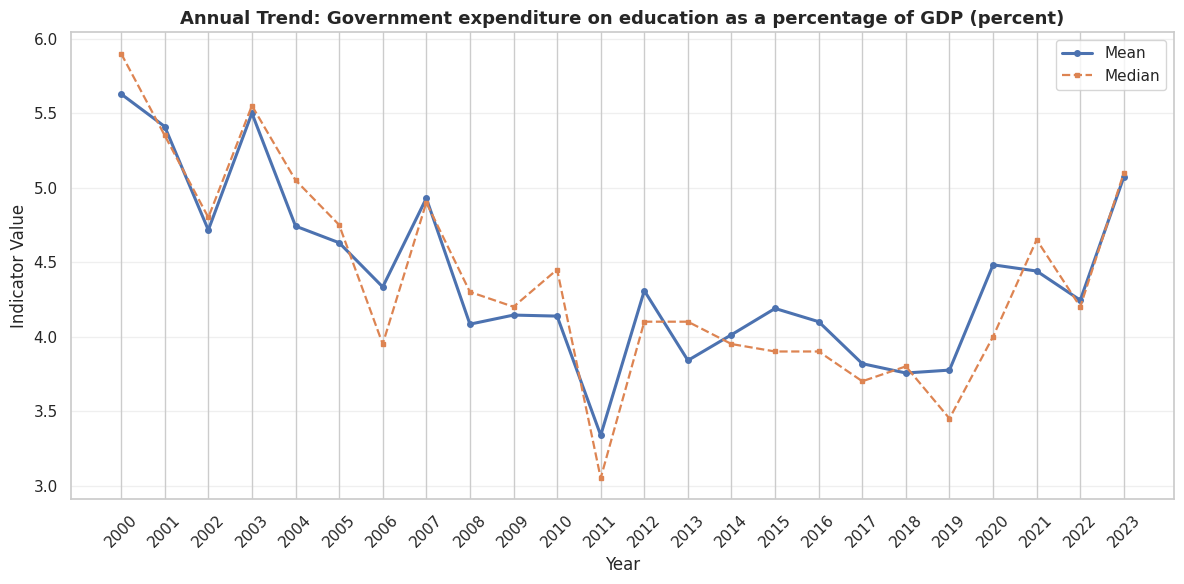

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/03_temporal_trends/trend_government_expenditure_on_education_as_a_percentage_of_gdp_percent.png


In [42]:
yearly_trends = (
    df.groupby(["Indicator", "Year"])["Value"]
    .agg(Mean="mean", Median="median", Count="count")
    .reset_index()
)

yearly_trends.to_csv(
    FOLDERS["reports"] / "yearly_trends_summary.csv",
    index=False
)

for indicator in df["Indicator"].drop_duplicates():
    subset = yearly_trends[
        yearly_trends["Indicator"] == indicator
    ].sort_values("Year")

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        subset["Year"], subset["Mean"],
        marker="o", markersize=4,
        linewidth=2.2, label="Mean"
    )
    ax.plot(
        subset["Year"], subset["Median"],
        marker="s", markersize=3,
        linewidth=1.6, linestyle="--",
        label="Median"
    )

    ax.set_title(
        f"Annual Trend: {indicator}",
        fontsize=13, weight="bold"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Indicator Value")
    ax.set_xticks(sorted(subset["Year"].unique()))
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=True)
    ax.grid(axis="y", alpha=0.3)

    save_plot(
        f"trend_{slugify(indicator)}.png",
        "trends"
    )

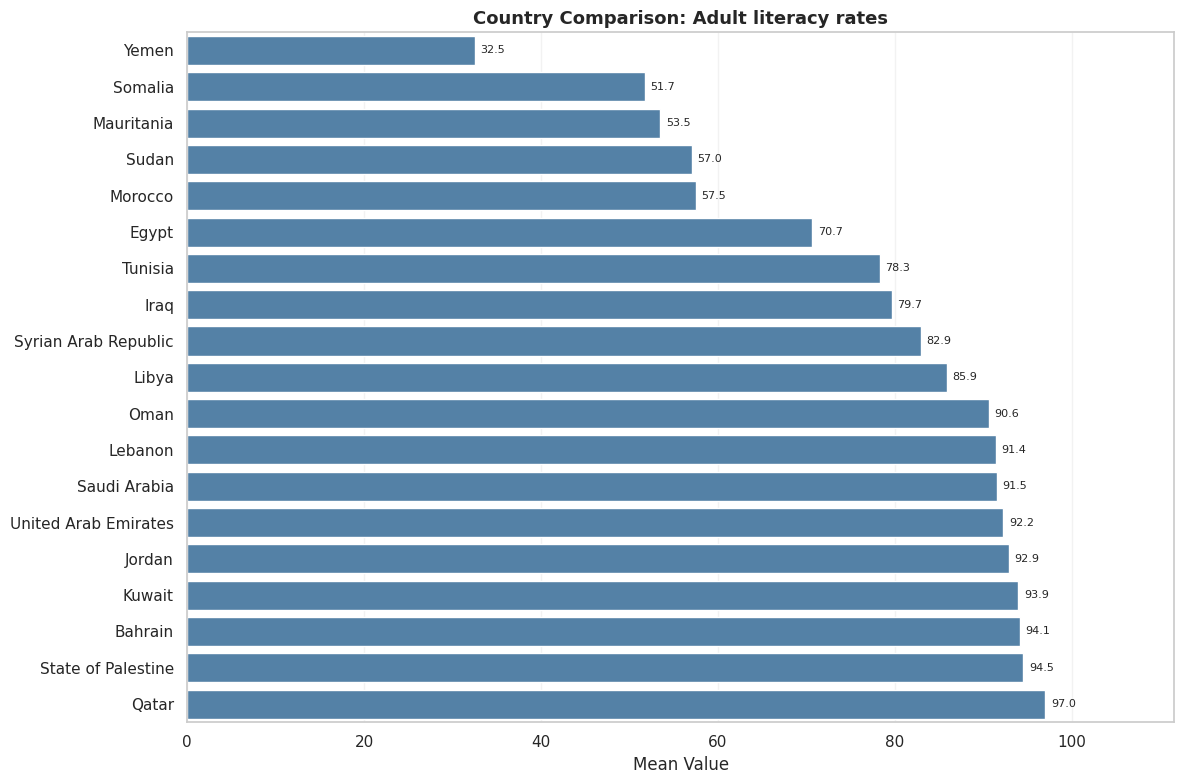

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_adult_literacy_rates.png


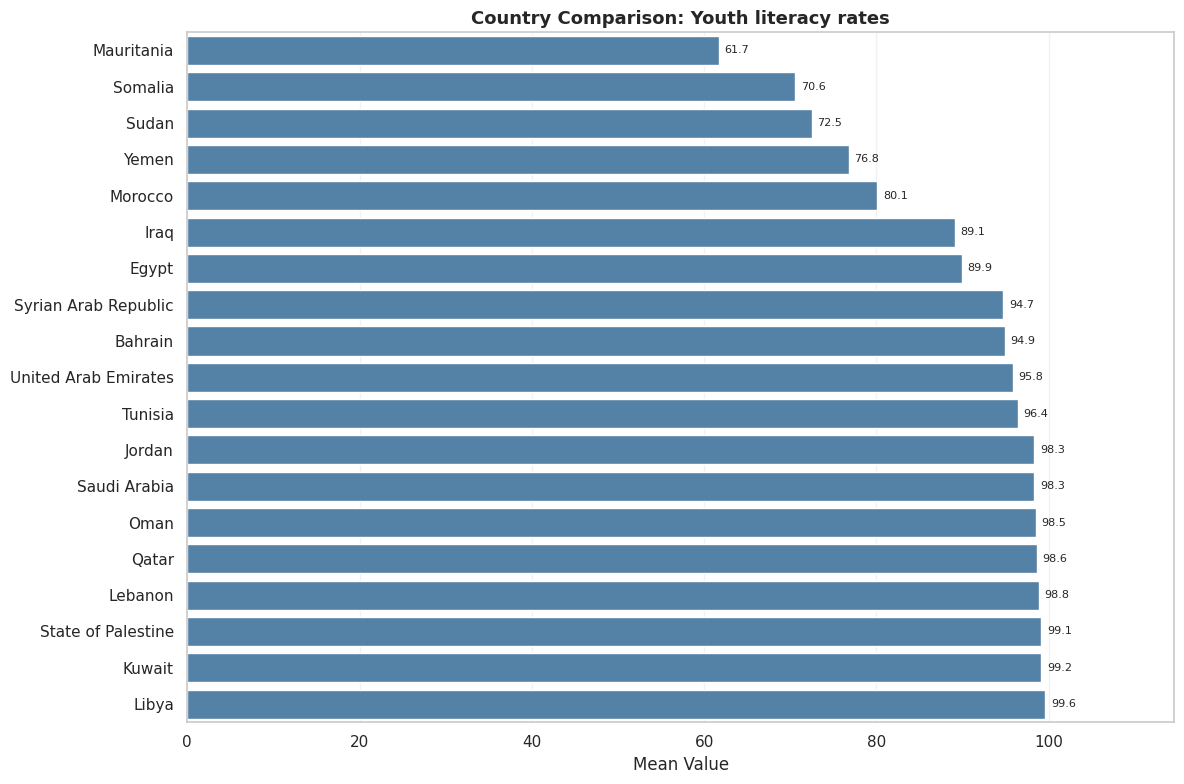

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_youth_literacy_rates.png


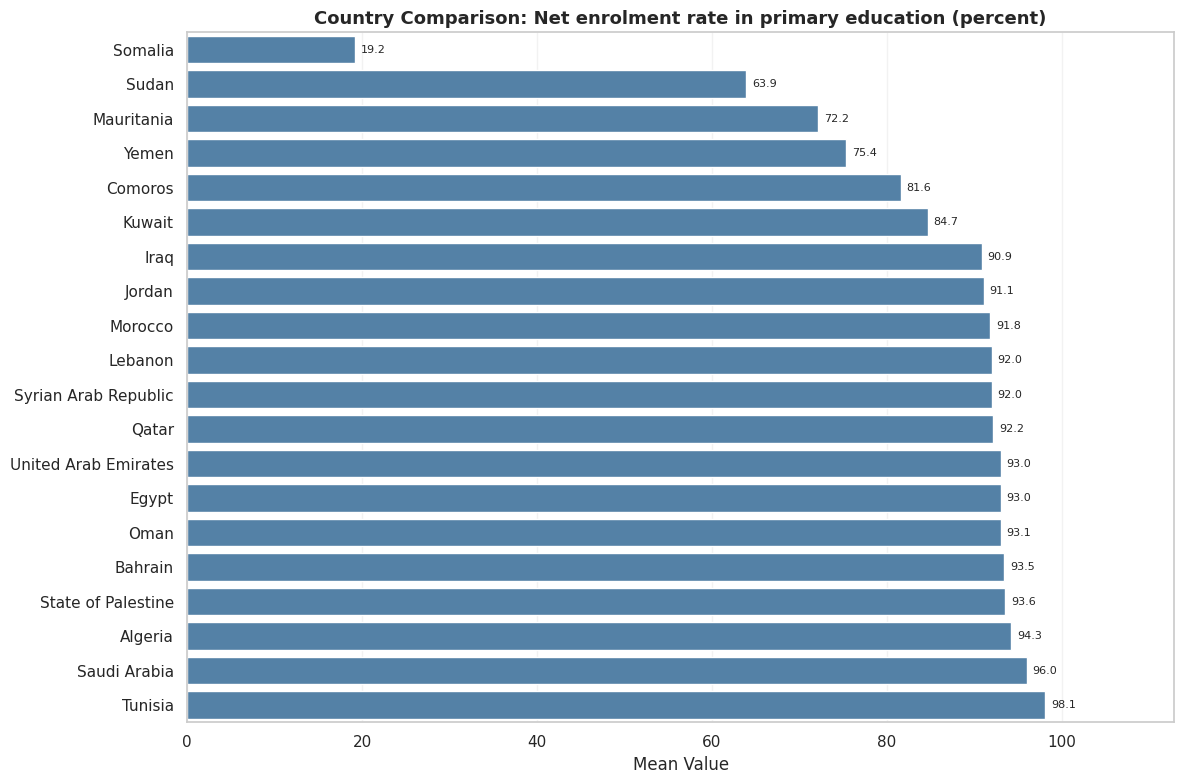

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_net_enrolment_rate_in_primary_education_percent.png


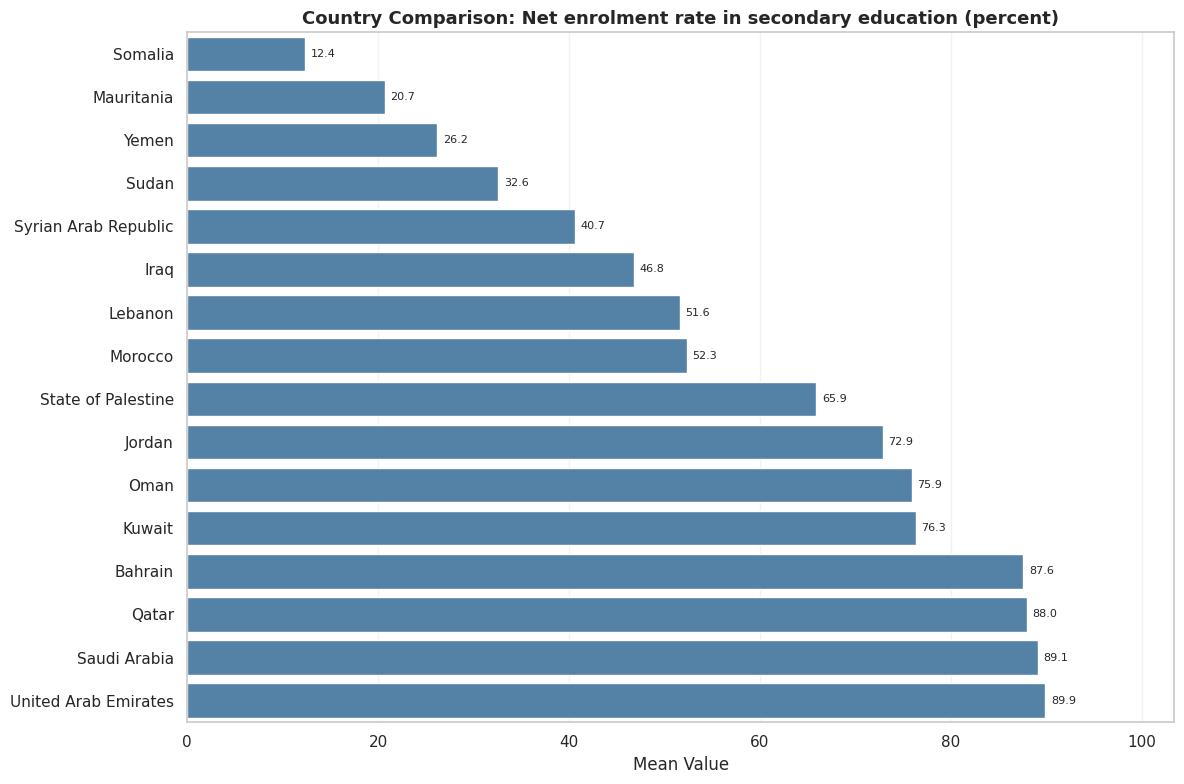

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_net_enrolment_rate_in_secondary_education_percent.png


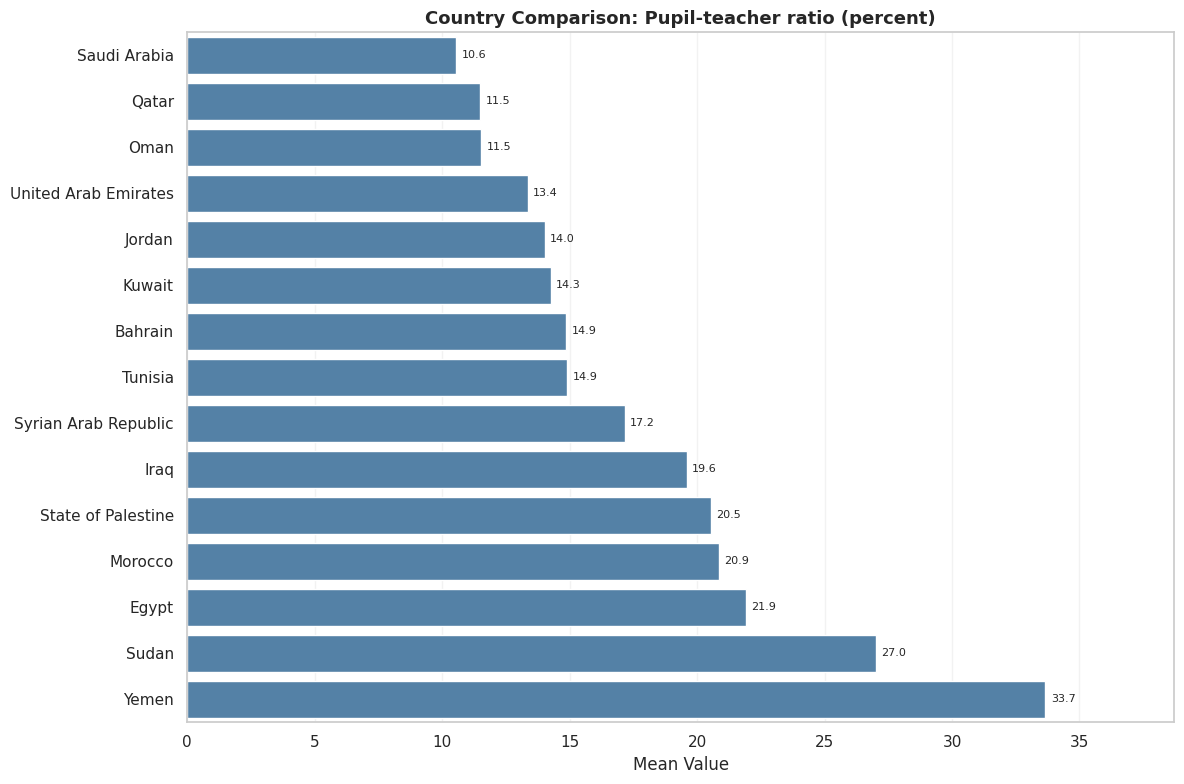

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_pupil_teacher_ratio_percent.png


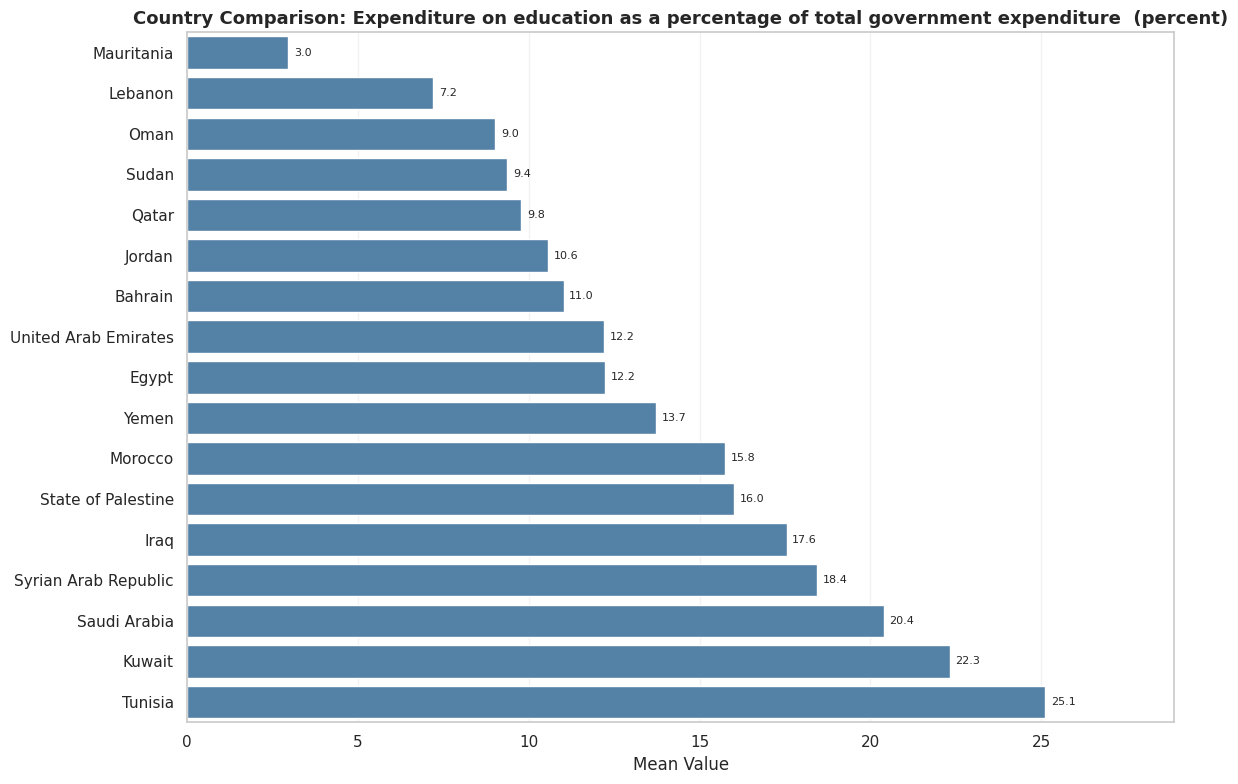

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_expenditure_on_education_as_a_percentage_of_total_government_expenditure_percent.png


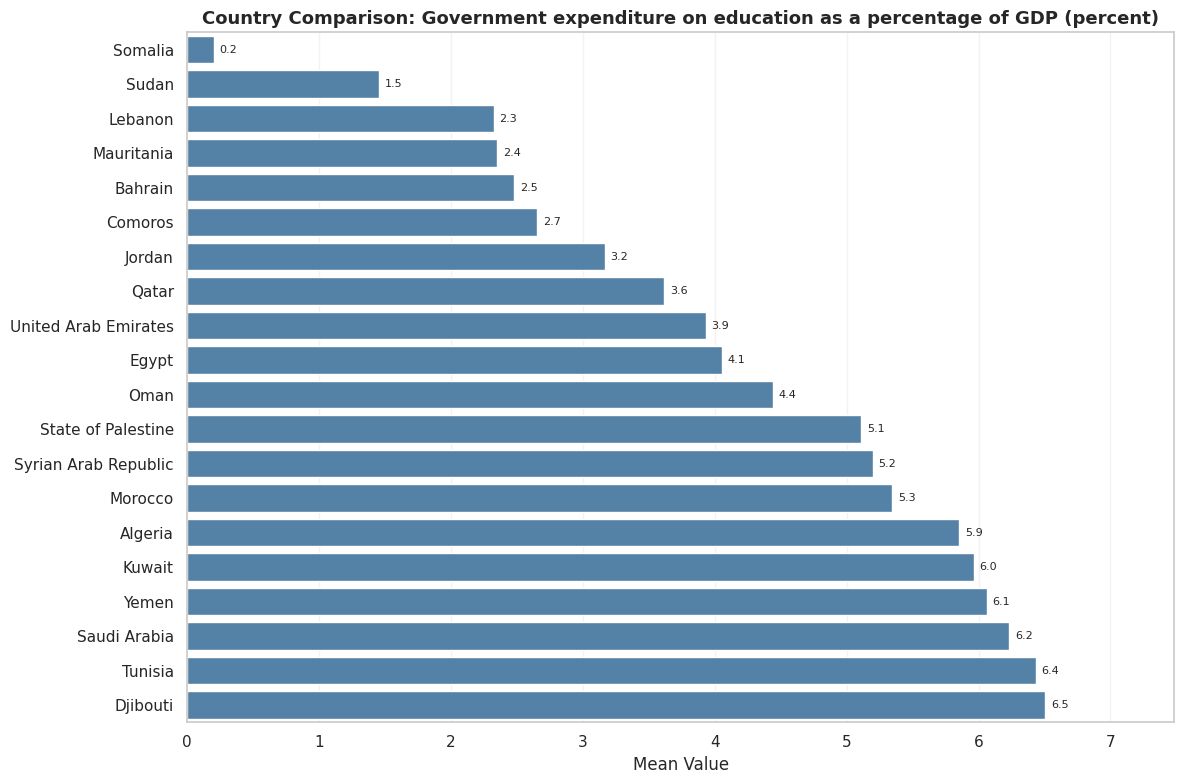

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/04_country_comparisons/countries_government_expenditure_on_education_as_a_percentage_of_gdp_percent.png


In [43]:
country_indicator_means = (
    df.groupby(["Indicator", "Country"])["Value"]
    .agg(Mean="mean", Median="median", Observations="count")
    .reset_index()
)

country_indicator_means.to_csv(
    FOLDERS["reports"] / "country_indicator_summary.csv",
    index=False
)

for indicator in df["Indicator"].drop_duplicates():
    subset = country_indicator_means[
        country_indicator_means["Indicator"] == indicator
    ].sort_values("Mean", ascending=True).copy()

    fig, ax = plt.subplots(figsize=(12, 8))

    sns.barplot(
        data=subset,
        x="Mean",
        y="Country",
        color="steelblue",
        ax=ax
    )

    max_value = subset["Mean"].max()
    ax.set_xlim(
        min(0, subset["Mean"].min() * 1.05),
        max_value * 1.15 if max_value > 0 else 1
    )

    for patch, value in zip(ax.patches, subset["Mean"]):
        ax.annotate(
            f"{value:.1f}",
            (patch.get_width(), patch.get_y() + patch.get_height() / 2),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=8
        )

    ax.set_title(
        f"Country Comparison: {indicator}",
        fontsize=13, weight="bold"
    )
    ax.set_xlabel("Mean Value")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

    save_plot(
        f"countries_{slugify(indicator)}.png",
        "countries"
    )

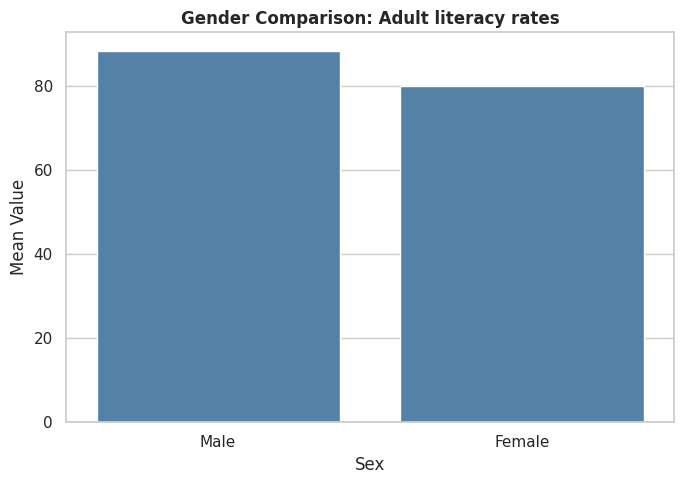

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/05_gender_analysis/gender_adult_literacy_rates.png


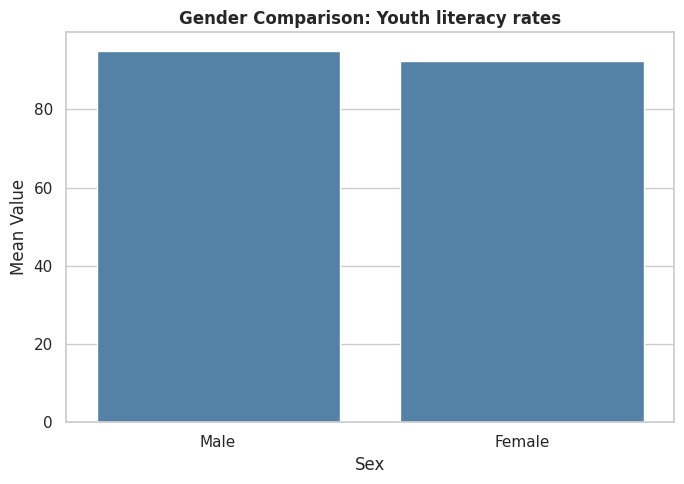

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/05_gender_analysis/gender_youth_literacy_rates.png


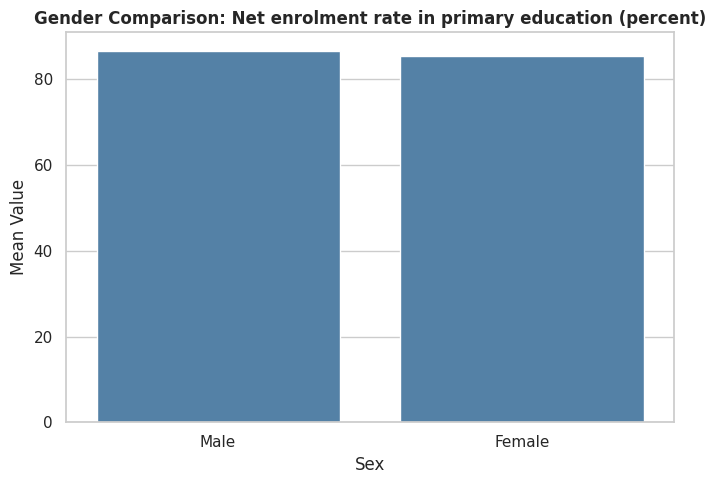

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/05_gender_analysis/gender_net_enrolment_rate_in_primary_education_percent.png


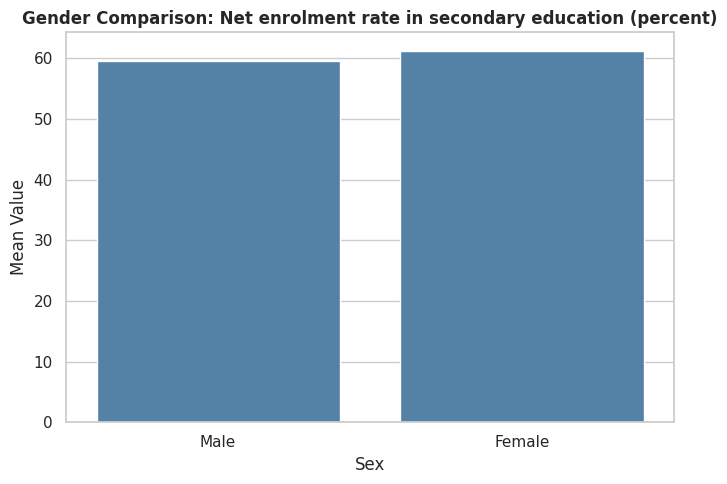

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/05_gender_analysis/gender_net_enrolment_rate_in_secondary_education_percent.png


,Indicator,Matched_Country_Years,Mean_Male,Mean_Female,Mean_Female_minus_Male,Median_Female_minus_Male
0,Adult literacy rates,145,88.381,80.091,-8.290,-5.0
1,Youth literacy rates,146,94.982,92.452,-2.529,-0.3
2,Net enrolment rate in primary education (percent),289,86.908,85.540,-1.367,0.0
3,Net enrolment rate in secondary education (per...,189,59.447,61.217,1.771,1.6


In [44]:
gender_indicators = [
    "Adult literacy rates",
    "Youth literacy rates",
    "Net enrolment rate in primary education (percent)",
    "Net enrolment rate in secondary education (percent)"
]

gender_data = df[
    df["Indicator"].isin(gender_indicators) &
    df["Sex"].isin(["Male", "Female"])
].copy()

# Select only aggregate values; do not mix detailed categories
gender_data = gender_data[
    gender_data["Nationality"].isin(["Total", "Not applicable"]) &
    gender_data["Educational_level"].isin(["Not applicable", "Total"]) &
    gender_data["Sector"].isin(["Not applicable", "Total"])
].copy()

# Collapse possible duplicate category combinations
gender_data = (
    gender_data.groupby(
        ["Country", "Year", "Indicator", "Sex"],
        as_index=False
    )["Value"].mean()
)

gender_summary = (
    gender_data.groupby(["Indicator", "Sex"])["Value"]
    .agg(Mean="mean", Median="median", Count="count")
    .reset_index()
)

gender_summary.to_csv(
    FOLDERS["reports"] / "gender_indicator_summary.csv",
    index=False
)

for indicator in gender_indicators:
    subset = gender_data[
        gender_data["Indicator"] == indicator
    ].copy()

    if subset.empty:
        print(f"Skipped: no usable data for {indicator}")
        continue

    # Descriptive plot
    summary = (
        subset.groupby("Sex")["Value"]
        .mean()
        .reindex(["Male", "Female"])
        .dropna()
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    sns.barplot(
        data=summary,
        x="Sex",
        y="Value",
        color="steelblue",
        ax=ax
    )

    ax.set_title(
        f"Gender Comparison: {indicator}",
        fontsize=12, weight="bold"
    )
    ax.set_xlabel("Sex")
    ax.set_ylabel("Mean Value")

    save_plot(
        f"gender_{slugify(indicator)}.png",
        "gender"
    )

# Compare paired country-year observations
paired_results = []

for indicator in gender_indicators:
    subset = gender_data[
        gender_data["Indicator"] == indicator
    ]

    paired = subset.pivot_table(
        index=["Country", "Year"],
        columns="Sex",
        values="Value",
        aggfunc="mean"
    ).dropna(subset=["Male", "Female"])

    if paired.empty:
        continue

    paired["Female_minus_Male"] = (
        paired["Female"] - paired["Male"]
    )

    paired_results.append({
        "Indicator": indicator,
        "Matched_Country_Years": len(paired),
        "Mean_Male": paired["Male"].mean(),
        "Mean_Female": paired["Female"].mean(),
        "Mean_Female_minus_Male": paired["Female_minus_Male"].mean(),
        "Median_Female_minus_Male": paired["Female_minus_Male"].median()
    })

paired_gender_results = pd.DataFrame(paired_results)

paired_gender_results.to_csv(
    FOLDERS["reports"] / "paired_gender_comparison.csv",
    index=False
)

display(paired_gender_results.round(3))


Nationality:
Indicator                                                                                          
Adult literacy rates                                                                 Total             151.0
                                                                                     Not applicable      NaN
Expenditure on education as a percentage of total government expenditure  (percent)  Total               NaN
                                                                                     Not applicable    189.0
Government expenditure on education as a percentage of GDP (percent)                 Total               NaN
                                                                                     Not applicable    235.0
Net enrolment rate in primary education (percent)                                    Total             334.0
                                                                                     Not applicable      NaN
Net enrolment 

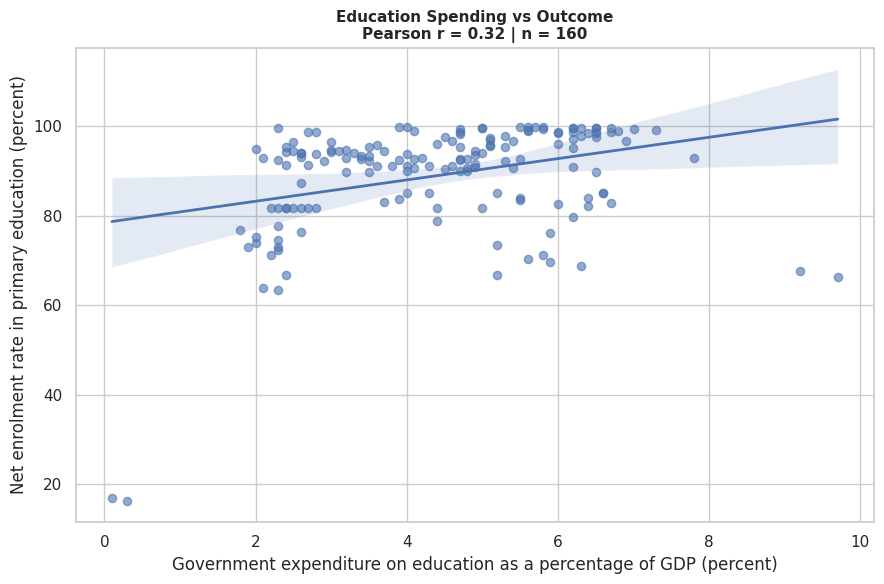

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_government_expenditure_on_education_as_a_percentage_of_gdp_percent_net_enrolment_rate_in_primary_education_percent.png


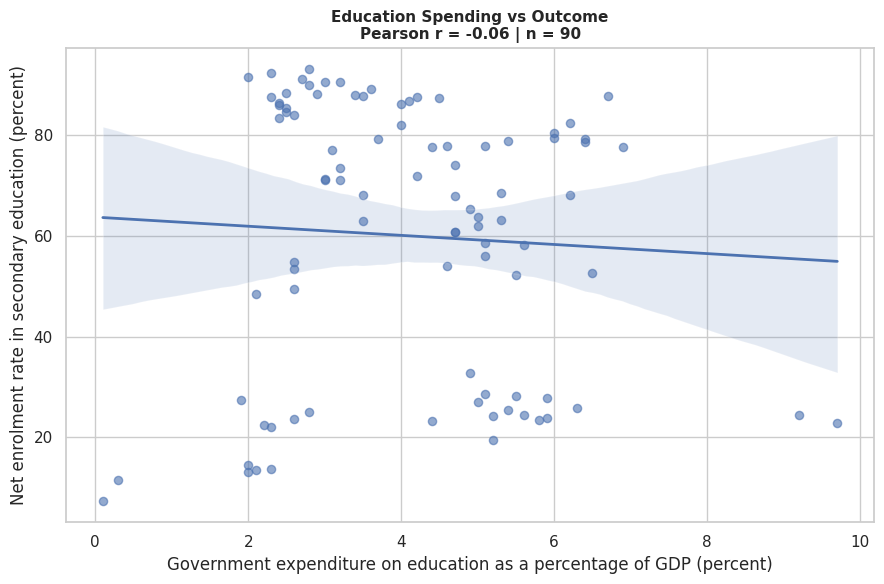

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_government_expenditure_on_education_as_a_percentage_of_gdp_percent_net_enrolment_rate_in_secondary_education_percent.png


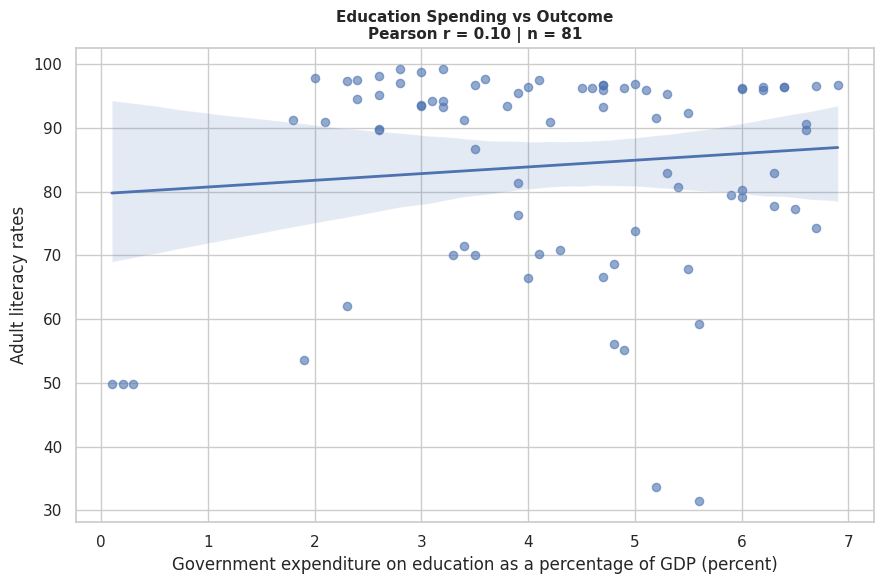

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_government_expenditure_on_education_as_a_percentage_of_gdp_percent_adult_literacy_rates.png


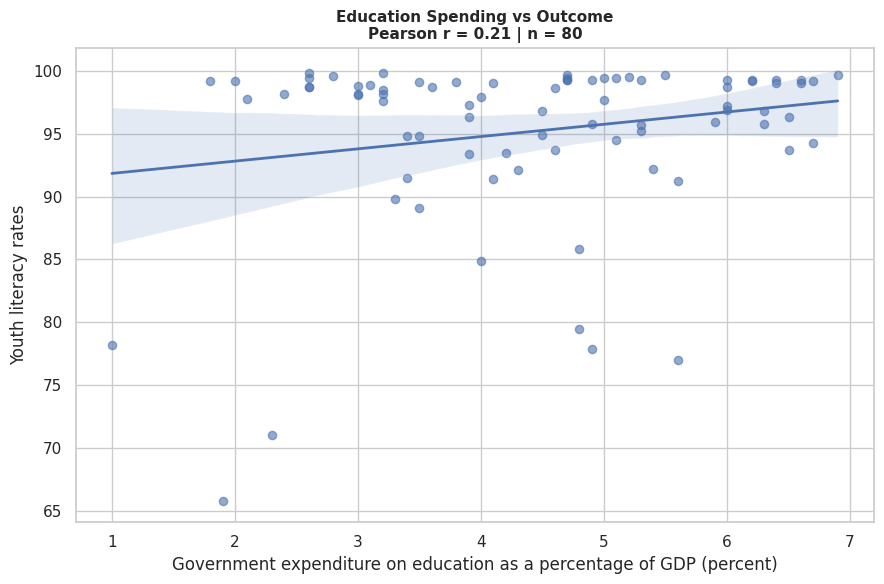

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_government_expenditure_on_education_as_a_percentage_of_gdp_percent_youth_literacy_rates.png


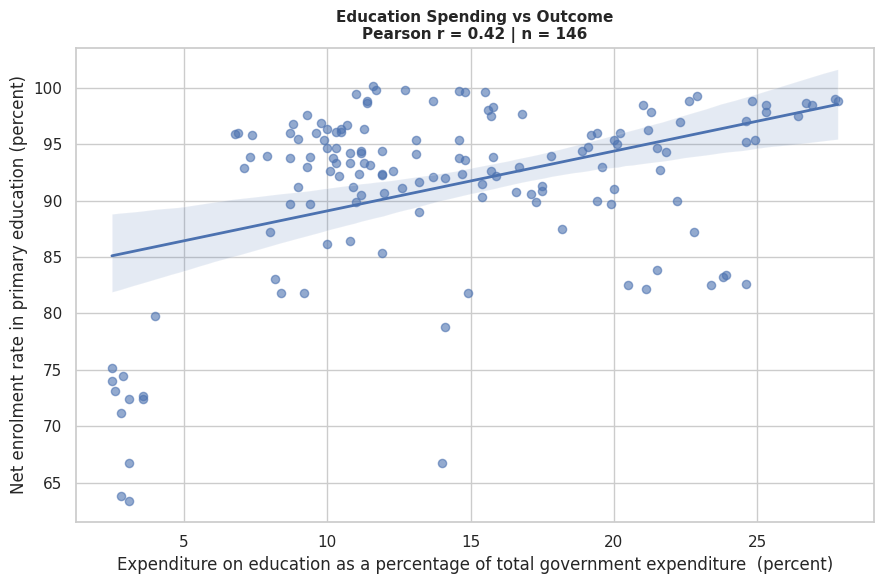

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_expenditure_on_education_as_a_percentage_of_total_government_expenditure_percent_net_enrolment_rate_in_primary_education_percent.png


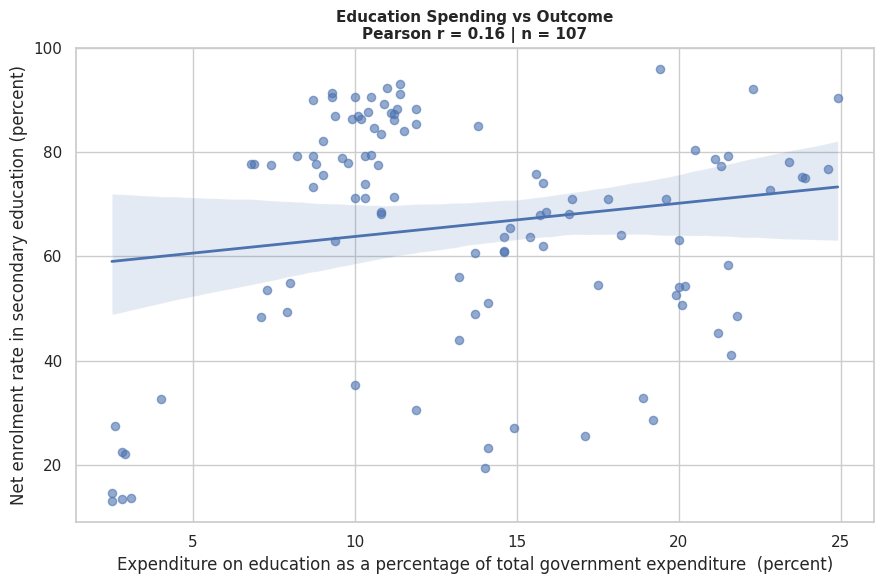

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_expenditure_on_education_as_a_percentage_of_total_government_expenditure_percent_net_enrolment_rate_in_secondary_education_percent.png


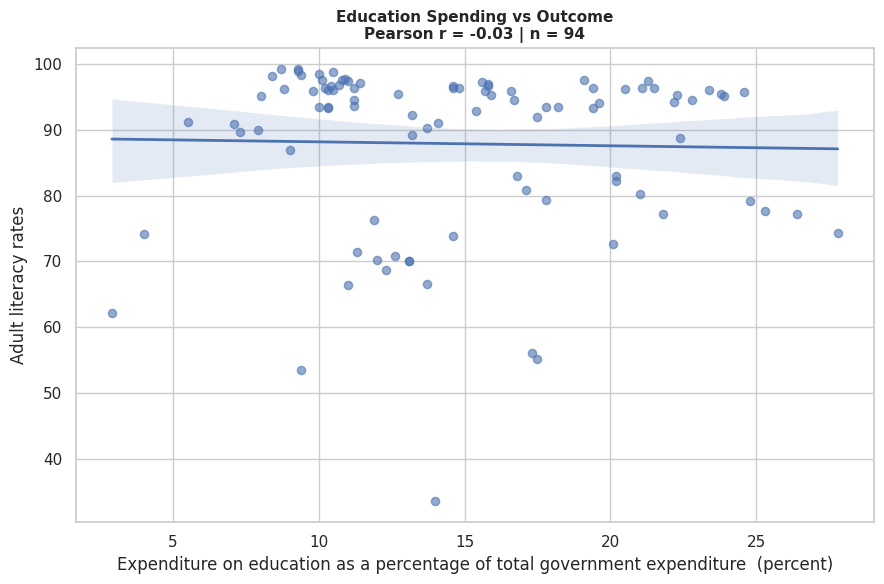

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_expenditure_on_education_as_a_percentage_of_total_government_expenditure_percent_adult_literacy_rates.png


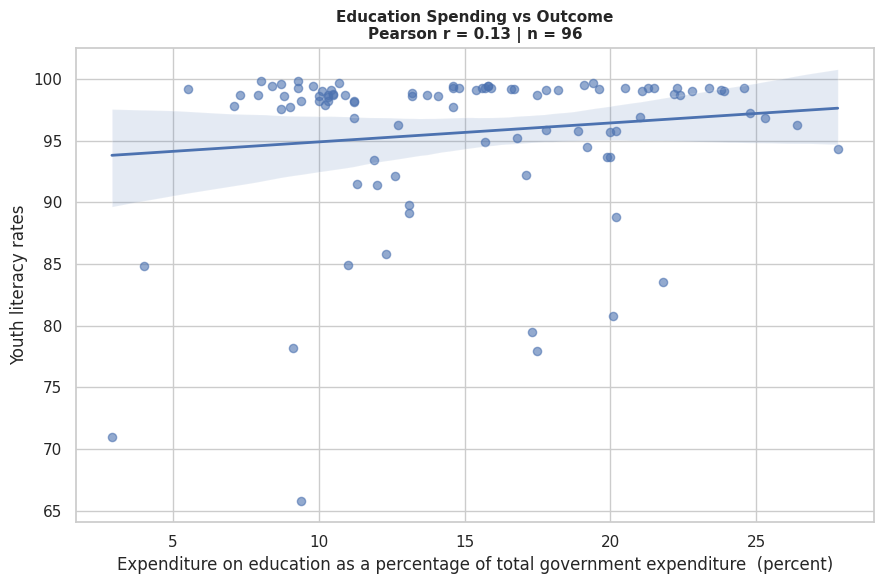

Saved: /home/youssef/Desktop/Data_Projects/DSS_Education/plots/06_spending_vs_outcomes/correlation_expenditure_on_education_as_a_percentage_of_total_government_expenditure_percent_youth_literacy_rates.png


,Spending_Indicator,Outcome_Indicator,Matched_Observations,Countries,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
4,Expenditure on education as a percentage of to...,Net enrolment rate in primary education (percent),146,16,0.4250,0.0000,0.2982,0.0003
0,Government expenditure on education as a perce...,Net enrolment rate in primary education (percent),160,17,0.3238,0.0000,0.3454,0.0000
3,Government expenditure on education as a perce...,Youth literacy rates,80,16,0.2067,0.0658,0.0798,0.4815
5,Expenditure on education as a percentage of to...,Net enrolment rate in secondary education (per...,107,13,0.1629,0.0936,-0.0143,0.8836
7,Expenditure on education as a percentage of to...,Youth literacy rates,96,16,0.1317,0.2008,0.0139,0.8933
2,Government expenditure on education as a perce...,Adult literacy rates,81,17,0.1036,0.3576,-0.0533,0.6366
6,Expenditure on education as a percentage of to...,Adult literacy rates,94,17,-0.0257,0.8057,-0.1631,0.1162
1,Government expenditure on education as a perce...,Net enrolment rate in secondary education (per...,90,12,-0.0583,0.5852,-0.0867,0.4167



All new plots and reports saved under:
/home/youssef/Desktop/Data_Projects/DSS_Education


In [45]:
spending_indicators = [
    "Government expenditure on education as a percentage of GDP (percent)",
    "Expenditure on education as a percentage of total government expenditure  (percent)"
]

outcome_indicators = [
    "Net enrolment rate in primary education (percent)",
    "Net enrolment rate in secondary education (percent)",
    "Adult literacy rates",
    "Youth literacy rates"
]

analysis_indicators = spending_indicators + outcome_indicators

analysis_data = df[
    df["Indicator"].isin(analysis_indicators)
].copy()

# Apply explicit aggregate filters where appropriate
analysis_data = analysis_data[
    (
        analysis_data["Sex"].isin(["Both sexes", "Not applicable"])
    ) &
    (
        analysis_data["Nationality"].isin(["Total", "Not applicable"])
    ) &
    (
        analysis_data["Educational_level"].isin(["Not applicable", "Total"])
    ) &
    (
        analysis_data["Sector"].isin(["Not applicable", "Total"])
    )
].copy()

# Show remaining category combinations before aggregation
for col in [
    "Nationality", "Sex", "Educational_level", "Sector"
]:
    print(f"\n{col}:")
    print(
        analysis_data.groupby("Indicator")[col]
        .apply(lambda s: s.value_counts().to_dict())
        .to_string()
    )

# Keep separate category combinations until the data have been audited.
# Average only within country-year-indicator after this explicit filter.
country_year_data = (
    analysis_data.groupby(
        ["Country", "Year", "Indicator"]
    )["Value"]
    .mean()
    .reset_index()
)

wide_data = country_year_data.pivot(
    index=["Country", "Year"],
    columns="Indicator",
    values="Value"
)

correlation_results = []

for spending in spending_indicators:
    for outcome in outcome_indicators:

        if spending not in wide_data.columns or outcome not in wide_data.columns:
            continue

        pair = wide_data[[spending, outcome]].dropna()

        if len(pair) < 3:
            print(f"Insufficient paired data: {spending} vs {outcome}")
            continue

        if pair[spending].nunique() < 2 or pair[outcome].nunique() < 2:
            print(f"Constant values; correlation skipped: {spending} vs {outcome}")
            continue

        pearson_r, pearson_p = pearsonr(
            pair[spending], pair[outcome]
        )
        spearman_rho, spearman_p = spearmanr(
            pair[spending], pair[outcome]
        )

        correlation_results.append({
            "Spending_Indicator": spending,
            "Outcome_Indicator": outcome,
            "Matched_Observations": len(pair),
            "Countries": pair.reset_index()["Country"].nunique(),
            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p
        })

        fig, ax = plt.subplots(figsize=(9, 6))

        sns.regplot(
            data=pair.reset_index(),
            x=spending,
            y=outcome,
            scatter_kws={"alpha": 0.6, "s": 35},
            line_kws={"linewidth": 2},
            ax=ax
        )

        ax.set_title(
            f"Education Spending vs Outcome\n"
            f"Pearson r = {pearson_r:.2f} | n = {len(pair)}",
            fontsize=11, weight="bold"
        )
        ax.set_xlabel(spending)
        ax.set_ylabel(outcome)

        save_plot(
            f"correlation_{slugify(spending)}_{slugify(outcome)}.png",
            "spending"
        )

correlation_table = pd.DataFrame(correlation_results)

if not correlation_table.empty:
    correlation_table = correlation_table.sort_values(
        "Pearson_r",
        ascending=False
    )

    display(correlation_table.round(4))

    correlation_table.to_csv(
        FOLDERS["reports"] / "education_spending_correlations.csv",
        index=False
    )
else:
    print(
        "No valid correlations were produced. "
        "Review the available aggregate categories first."
    )

print("\nAll new plots and reports saved under:")
print(PROJECT_DIR)

# Feature Extraction & Selection

In [ ]:
# Keep the original dataframe unchanged
model_df = df.copy()

# Ensure correct data types
model_df["Year"] = pd.to_numeric(model_df["Year"], errors="coerce")
model_df["Value"] = pd.to_numeric(model_df["Value"], errors="coerce")

# Remove rows with missing target or year
model_df = model_df.dropna(subset=["Year", "Value"]).copy()
model_df["Year"] = model_df["Year"].astype(int)

# Feature Extraction
model_df["Years_Since_2000"] = model_df["Year"] - 2000
model_df["Year_Squared"] = model_df["Years_Since_2000"] ** 2

In [57]:
categorical_features = [
    "Indicator",
    "Country",
    "Nationality",
    "Sex",
    "Educational_level",
    "Sector"
]

numerical_features = [
    "Years_Since_2000",
    "Year_Squared"
]

# Keep only required columns
features = categorical_features + numerical_features
target = "Value"

model_df = model_df[
    features + ["Year", target]
].copy()

# Remove any remaining missing feature values
model_df = model_df.dropna(
    subset=features + [target]
)

model_df = model_df.sort_values("Year").reset_index(drop=True)

In [58]:
# Display dataset information
print("Dataset shape:", model_df.shape)
print("\nFeatures:")
print(features)
print("\nTarget:", target)
print("\nMissing values:")
print(model_df.isna().sum())

Dataset shape: (5055, 10)

Features:
['Indicator', 'Country', 'Nationality', 'Sex', 'Educational_level', 'Sector', 'Years_Since_2000', 'Year_Squared']

Target: Value

Missing values:
Indicator            0
Country              0
Nationality          0
Sex                  0
Educational_level    0
Sector               0
Years_Since_2000     0
Year_Squared         0
Year                 0
Value                0
dtype: int64


# Encoding

In [59]:
# One-Hot Encoding
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_array = encoder.fit_transform(model_df[categorical_features])
encoded_columns = encoder.get_feature_names_out(categorical_features)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=model_df.index
)

In [60]:
# Combine encoded and numerical features
X_encoded = pd.concat(
    [
        model_df[numerical_features],
        encoded_df
    ],
    axis=1
)

y = model_df[target].copy()

print("Encoded features shape:", X_encoded.shape)
print("Target shape:", y.shape)
print("\nSample encoded features:")
display(X_encoded.head())

Encoded features shape: (5055, 49)
Target shape: (5055,)

Sample encoded features:


,Years_Since_2000,Year_Squared,Indicator_Adult literacy rates,Indicator_Expenditure on education as a percentage of total government expenditure (percent),Indicator_Government expenditure on education as a percentage of GDP (percent),Indicator_Net enrolment rate in primary education (percent),Indicator_Net enrolment rate in secondary education (percent),Indicator_Pupil-teacher ratio (percent),Indicator_Youth literacy rates,Country_Algeria,...,Educational_level_Not applicable,Educational_level_Preparatory,Educational_level_Primary,Educational_level_Secondary,Educational_level_Tertiary,Educational_level_Total,Sector_Not applicable,Sector_Private,Sector_Public,Sector_Total
0,0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


# Scaling

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = X_encoded.copy()

# Scale numerical features only
X_scaled[numerical_features] = scaler.fit_transform(
    X_encoded[numerical_features]
)

print("Scaled features shape:", X_scaled.shape)
print("\nScaled numerical features:")
display(X_scaled[numerical_features].head())

print("\nFinal target:")
display(y.head())

Scaled features shape: (5055, 49)

Scaled numerical features:


,Years_Since_2000,Year_Squared
0,-1.926011,-1.259589
1,-1.926011,-1.259589
2,-1.926011,-1.259589
3,-1.926011,-1.259589
4,-1.926011,-1.259589



Final target:


0    79.3
1    68.8
2    59.1
3    64.0
4     9.7
Name: Value, dtype: float64

In [62]:
from pathlib import Path

output_dir = Path(
    "/home/youssef/Desktop/Data_Projects/DSS_Education/modeling"
)
output_dir.mkdir(parents=True, exist_ok=True)

X_encoded.to_csv(
    output_dir / "X_encoded.csv",
    index=True
)

X_scaled.to_csv(
    output_dir / "X_scaled.csv",
    index=True
)

y.to_frame().to_csv(
    output_dir / "target.csv",
    index=True
)

print("Modeling files saved to:", output_dir)

Modeling files saved to: /home/youssef/Desktop/Data_Projects/DSS_Education/modeling


# Train/Test Split

In [63]:
years = np.sort(model_df["Year"].unique())
if len(years) < 5:
    raise ValueError("Not enough unique years for temporal evaluation.")

# Reserve the latest 20% of unique years for testing
n_test_years = max(1, int(np.ceil(len(years) * 0.20)))
test_years = years[-n_test_years:]
first_test_year = test_years[0]

train_df = model_df[
    model_df["Year"] < first_test_year
].copy()

test_df = model_df[
    model_df["Year"] >= first_test_year
].copy()

In [64]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

In [65]:
print("Training years:", train_df["Year"].min(), "-", train_df["Year"].max())
print("Testing years:", test_df["Year"].min(), "-", test_df["Year"].max())

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test years:", test_years)

Training years: 2000 - 2018
Testing years: 2019 - 2023
Training rows: 4358
Testing rows: 697
Test years: [2019 2020 2021 2022 2023]


# Preprocessing & Pipeliens

In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [68]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ],
    remainder="drop"
)

In [69]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=3,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    )
}

In [70]:
# XGBoost - optional
try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost is not installed; skipping it.")


# CatBoost - optional
try:
    from catboost import CatBoostRegressor

    models["CatBoost"] = CatBoostRegressor(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        verbose=0,
        random_seed=42,
        allow_writing_files=False
    )

except ImportError:
    print("CatBoost is not installed; skipping it.")

print("Models to train:", list(models.keys()))

CatBoost is not installed; skipping it.
Models to train: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'AdaBoost', 'KNN', 'SVR', 'XGBoost']


# Train Models

In [72]:
results = []
predictions = {}

for model_name, model in models.items():

    print(f"Training: {model_name}")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    try:
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        predictions[model_name] = {
            "pipeline": pipeline,
            "y_pred": y_pred
        }

        print(
            f"MAE: {mae:.4f} | "
            f"RMSE: {rmse:.4f} | "
            f"R2: {r2:.4f}"
        )

    except Exception as e:
        print(f"Failed: {model_name} | {e}")

Training: Linear Regression
MAE: 7.4218 | RMSE: 9.9863 | R2: 0.9263
Training: Decision Tree
MAE: 4.8678 | RMSE: 7.8544 | R2: 0.9544
Training: Random Forest
MAE: 3.3587 | RMSE: 6.0945 | R2: 0.9726
Training: Gradient Boosting
MAE: 4.9778 | RMSE: 6.8318 | R2: 0.9655
Training: AdaBoost
MAE: 10.9125 | RMSE: 14.0067 | R2: 0.8550
Training: KNN
MAE: 5.0511 | RMSE: 10.3078 | R2: 0.9215
Training: SVR
MAE: 6.9023 | RMSE: 11.3943 | R2: 0.9041
Training: XGBoost
MAE: 3.9331 | RMSE: 6.1872 | R2: 0.9717


In [73]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,R2
0,Random Forest,3.358733,6.094540,0.972553
1,XGBoost,3.933091,6.187158,0.971713
2,Decision Tree,4.867769,7.854415,0.954414
3,Gradient Boosting,4.977790,6.831820,0.965511
4,KNN,5.051119,10.307831,0.921487
5,SVR,6.902342,11.394328,0.904064
6,Linear Regression,7.421804,9.986296,0.926309
7,AdaBoost,10.912537,14.006709,0.855030


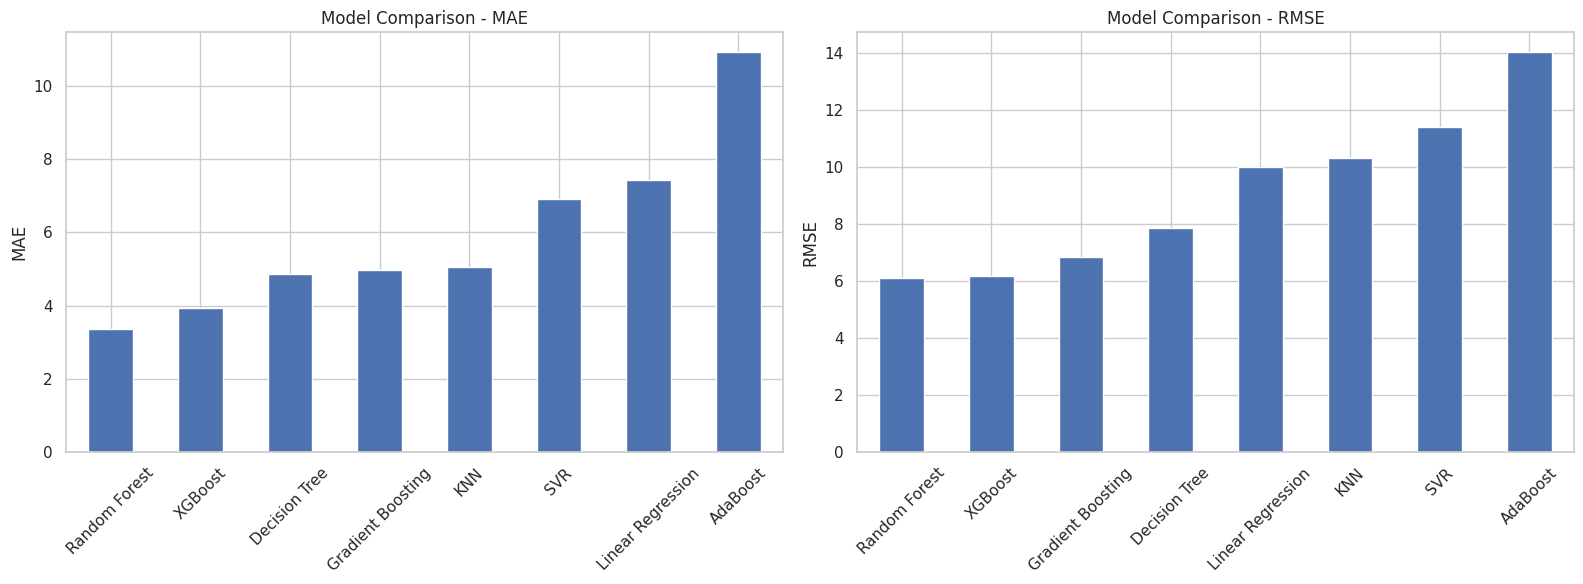

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
results_df.sort_values("MAE").plot(
    x="Model",
    y="MAE",
    kind="bar",
    ax=axes[0],
    legend=False,
    title="Model Comparison - MAE"
)

results_df.sort_values("RMSE").plot(
    x="Model",
    y="RMSE",
    kind="bar",
    ax=axes[1],
    legend=False,
    title="Model Comparison - RMSE"
)

axes[0].set_ylabel("MAE")
axes[1].set_ylabel("RMSE")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Best model by MAE: Random Forest


,Year,Country,Indicator,Value,Predicted_Value,Absolute_Error
4358,2019,Qatar,Net enrolment rate in secondary education (per...,90.8,90.925839,0.125839
4359,2019,Qatar,Net enrolment rate in secondary education (per...,90.0,91.009270,1.009270
4360,2019,Qatar,Net enrolment rate in secondary education (per...,88.3,91.375678,3.075678
4361,2019,Qatar,Net enrolment rate in secondary education (per...,89.9,91.008933,1.108933
4362,2019,Qatar,Net enrolment rate in secondary education (per...,89.1,91.155485,2.055485
4363,2019,Qatar,Net enrolment rate in secondary education (per...,90.9,90.492964,0.407036
4364,2019,Qatar,Net enrolment rate in secondary education (per...,92.4,90.724406,1.675594
4365,2019,Iraq,Net enrolment rate in primary education (percent),91.0,94.346060,3.346060
4366,2019,Iraq,Net enrolment rate in primary education (percent),89.0,91.822746,2.822746
4367,2019,Iraq,Net enrolment rate in primary education (percent),90.0,93.079105,3.079105


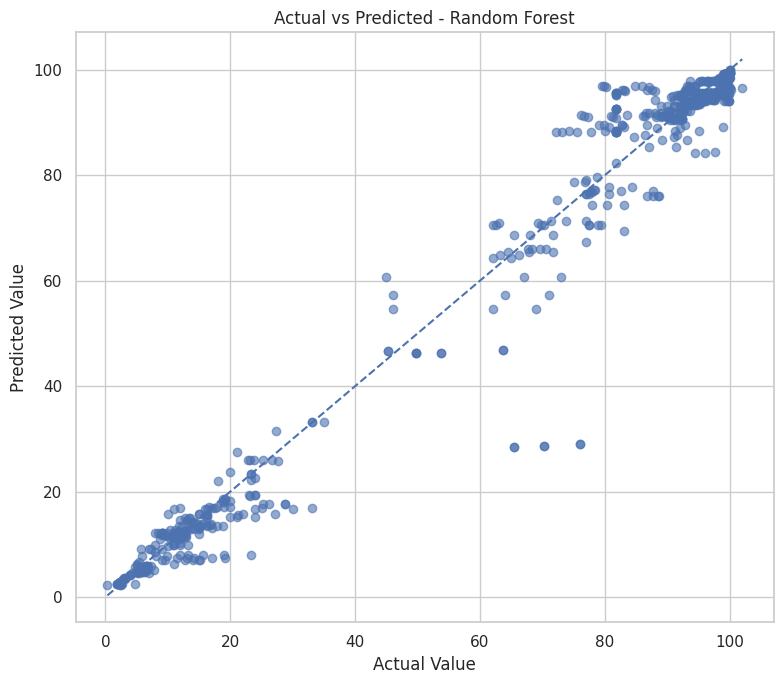

In [75]:
if not results_df.empty:

    best_model_name = results_df.iloc[0]["Model"]
    best_predictions = predictions[best_model_name]["y_pred"]

    comparison_df = test_df[
        ["Year", "Country", "Indicator", target]
    ].copy()

    comparison_df["Predicted_Value"] = best_predictions
    comparison_df["Absolute_Error"] = (
        comparison_df[target] - comparison_df["Predicted_Value"]
    ).abs()

    print("Best model by MAE:", best_model_name)
    display(comparison_df.head(20))

    plt.figure(figsize=(8, 7))

    plt.scatter(
        comparison_df[target],
        comparison_df["Predicted_Value"],
        alpha=0.6
    )

    min_val = min(
        comparison_df[target].min(),
        comparison_df["Predicted_Value"].min()
    )

    max_val = max(
        comparison_df[target].max(),
        comparison_df["Predicted_Value"].max()
    )

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    plt.xlabel("Actual Value")
    plt.ylabel("Predicted Value")
    plt.title(f"Actual vs Predicted - {best_model_name}")
    plt.tight_layout()
    plt.show()

else:
    print("No models completed successfully.")

# Save Models

In [77]:
from pathlib import Path
import joblib
import json

output_dir = Path(
    "/home/youssef/Desktop/Data_Projects/DSS_Education/modeling"
)

output_dir.mkdir(parents=True, exist_ok=True)

In [78]:
# Save the current best model
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = predictions[best_model_name]["pipeline"]

joblib.dump(
    best_pipeline,
    output_dir / "best_model_random_forest.joblib"
)

# Save XGBoost as a challenger model if available
if "XGBoost" in predictions:
    joblib.dump(
        predictions["XGBoost"]["pipeline"],
        output_dir / "xgboost_model.joblib"
    )

# Save model comparison results
results_df.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

In [79]:
# Save model configuration
model_info = {
    "best_model": best_model_name,
    "target": "Value",
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "training_year_min": int(train_df["Year"].min()),
    "training_year_max": int(train_df["Year"].max()),
    "testing_year_min": int(test_df["Year"].min()),
    "testing_year_max": int(test_df["Year"].max()),
    "note": "Preliminary temporal evaluation; validate before future forecasting."
}

with open(
    output_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(model_info, f, indent=4, ensure_ascii=False)

print("Saved best model:", best_model_name)
print("Saved to:", output_dir)

Saved best model: Random Forest
Saved to: /home/youssef/Desktop/Data_Projects/DSS_Education/modeling


In [80]:
import joblib

saved_model = joblib.load(
    output_dir / "best_model_random_forest.joblib"
)

print("Model loaded successfully:")
print(saved_model)

# Test prediction on the existing test set
sample_predictions = saved_model.predict(X_test.head(5))

print("\nSample predictions:")
print(sample_predictions)

Model loaded successfully:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Indicator', 'Country',
                                                   'Nationality', 'Sex',
                                                   'Educational_level',
                                                   'Sector']),
                                                 ('numerical', StandardScaler(),
                                                  ['Years_Since_2000',
                                                   'Year_Squared'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, min_samples_leaf=2,
                                       n_estimators=200, n_jobs=-1,
                          